# CSC 349A Numerical Analysis - Lecture 6 - Taylor's Theorem
**Truncation errors** occur when some exact mathematical procedure is
replaced by a finite approximation. For example,


* Approximation of a function by a finite number of terms in its Taylor series:
$$
e^{x} \approx 1 + x + \frac{x^2}{2} + \frac{x^3}{6}
$$
* Approximation of a derivative by a finite difference: 
$$
\frac{dv}{dt}|_{t=t_i} \approx \frac{v(t_{i+1}) - v(t_{i})}{t_{i+1} - t_{i}}
$$
* Approximation of a definite integral by a finite sum of function values:
$$
\int_{a}^{b} f(x)dx \approx \frac{b-a}{2} \left[ f(a) + f(b) \right]
$$

Taylor's Theorem is the fundamental tool for deriving and analyzing numerical
approximation formulas in this course. It states that any "smooth"
function (one with a sufficient number of derivatives) can be
approximated by a polynomial, and it includes an error (remainder)
term that indicates how accurate the polynomial approximation
is. Taylor's theorem also provides a means to estimate the value of a
function $f(x)$ at some point $x_{i+1}$ using the values of $f(x)$ and
its derivatives at some nearby point $x_{i}$.

## Taylor's Theorem
Let $n \geq 0$ and let $a$ be any constant. If $f(x)$ and its first $n+1$ derivatives are continuous on some interval containing $x$ and $a$, then: 

$$
 f(x) = f(a) + f'(a)(x-a) + \frac{f''(a)}{2!}(x-a)^2 + \frac{f'''(a)}{3!}(x-a)^3 + \dots + \frac{f^{n}(a)}{n!}(x-a)^{n} + R_n
$$
where the remainder (or error) term is: 
$$
R_{n} = \frac{f^{(n+1)}(\xi)}{(n+1)!} (x-a)^{n+1} 
$$

and $\xi$ is some value between $x$ and $a$. Note that: 

$$
P_n(x) = f(a) + f'(a)(x-a) + \frac{f''(a)}{2!}(x-a)^2 + \frac{f'''(a)}{3!}(x-a)^3 + \dots + \frac{f^{n}(a)}{n!}(x-a)^{n} 
$$

is a polynomial of degree $n$ in $x$, and is called the **Taylor polynomial approximation of degree $n$** for $f(x)$ expanded about $x=a$. $R_{n}$ is the **truncation error** of this polynomial approximation to $f(x)$.  

## Taylor Example 1
Determine the Taylor polynomial approximation of order $n=3$ for 
$f(x) = \ln(x+1)$ expanded about $a=0$ (McLaurin series when 
$a=0$). 

\begin{eqnarray} 
f(x) =& \ln(x+1), & f(0) = 0 \\ 
f'(x) =& \frac{1}{x+1}, & f'(0) = 1 \\ 
f''(x) =& \frac{-1}{(x+1)^2}, & f''(0) = -1 \\ 
f'''(x) =& \frac{2}{(x+1)^3}, & f'''(0) = 2 
\end{eqnarray}

Thus: 
\begin{eqnarray*} 
\ln(x+1) &=& f(a) + f'(a)(x-a) + \frac{f''(a)}{2!}(x-a)^2 + \frac{f'''(a)}{3!}(x-a)^3 + \dots + \frac{f^{n}(a)}{n!}(x-a)^{n} \\ &=&  
f(0) + f'(0) + \frac{f''(0)}{2} x^2 +\frac{f'''(0)}{6}x^{3} \\ 
&=&  x -\frac{x^2}{2} + \frac{x^3}{3} 
\end{eqnarray*}

**How accurate is this polynomial approximation?**

Let $P_3(x) = x - \frac{x^2}{2} + \frac{x^{3}}{3}$. Since 
$f^{(4)} (x) = \frac{-6}{(x+1)^4}$, for each value of $x$ there 
exists a value $\xi$ such that: 
$$
\ln(x+1) - P_{3}(x) = R_n = \frac{f^{(4)}(\xi)}{4!}x^4 = \frac{-x^4}{4(\xi +1)^4}
$$

where $\xi$ is some number between $x$ and $a=0$. 

For example, if $x=0.25$ then 
$$
ln(1.25) \approx 0.25 - \frac{(0.25)^2}{2} + \frac{(0.25)^3}{3} = 0.223958333 \dots 
$$
and the trunaction error of this approximation is: 
$$
R_3 = \frac{-(0.25)^4}{4(\xi+1)^4} = \frac{-1}{1024(\xi+1)^4}
$$

for some value of $\xi$ such that $0\leq \xi \leq 0.25$. 

It is not possible to determine the value of $\xi$ that gives the exact 
value of $R_3$, but it is possible to determine an **upper bound** for 
this truncation error: 

$$
|R_{3}| = \left| \frac{-1}{1024(\xi_1)^4}\right| \leq \frac{1}{1024(0+1)^4} = 0.0009765625
$$

This gives a guaranteed upper bound for the truncation error in the above approximation to $\ln(1.25)$. Note that the actual (absolute) error is: 

$$
|E_t| = |0.22314335 - 0.22395833| = 0.00081478
$$

Rather than just using the Taylor polynomial approximation to estimate the value of a function at one specified point, it is more common to use the polynomial approximation **for an entire interval of values $x$**. In such a case, it is also desirable to be able to determine the accuracy (that is an upper bound for the error). For example, suppose that 

$$
\ln(x+1) \approx x - \frac{x^2}{2} + \frac{x^3}{3} 
$$

for any value $x \in [0, 0.5]$. Then for any value of $x \in [0, 0.5]$, 
$$
| \ln(x+1) - P_3(x)| = \left| \frac{-x^4}{4(\xi +1)^4} \right | \leq \left | \frac{(0.5)^4}{4(0+1)^4}\right| = 0.015625
$$
 
since $\max\limits_{0 \leq x \leq 0.5} |x^4| = (0.5)^4$ and, as $\xi$ lies between $0$ and $x$, $\max\limits_{0 \leq \xi \leq 0.5} \frac{1}{|(\xi + 1)^4|} = 1$. 

To illustrate Taylor's approximation I plotted this functon $f(x)=ln(x+1)$ against three different approximations, $P_1(x)=x$, $P_2(x) = x - \frac{x^2}{2}$, and $P_3(x)=x-\frac{x^2}{2}+\frac{x^3}{3}$. The commands and plot are shown below:

C:\Users\vuthu\AppData\Local\Temp\ipykernel_25304\3433968157.py:5: RuntimeWarning: divide by zero encountered in log
  fx = np.log(x+1)


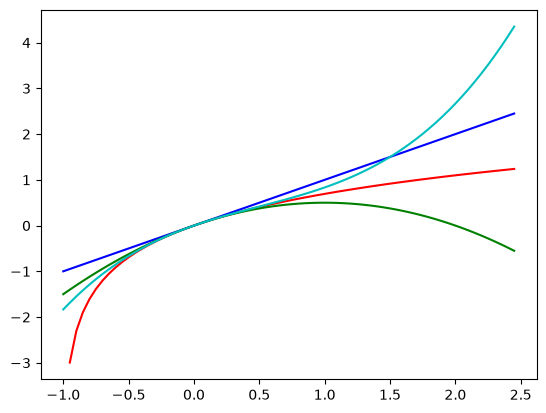

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(-1,2.5,.05)
fx = np.log(x+1)
Px1 = x
Px2 = x - x**2/2
Px3 = Px2 + x**3/3
plt.plot(x,fx,'r',x,Px1,'b',x,Px2,'g',x,Px3,'c');

## Taylor Example 2
Let $x_{i+1} = x_{i} + h$ so that $h = x_{i+1} - x_{i}$. Then Taylor's theorem for $f(x)$ expanded about $x_{i}$, and evaluated at $x=x_{i+1}$ is: 

$$ 
f(x_{i+1}) = f(x_i) + f'(x_i) h + \frac{f''(x_i)}{2!}h^2 + \frac{f'''(x_i)}{3!}h^3 + \dots + \frac{f^{n}(x_i)}{n!}h^n + R_{n}  
$$

Letting $n=1$, this gives 
$$
f(x_{i+1}) = f(x_i) + f'(x_i) h + R_1
$$

which implies that: 
$$
f'(x_i)  = \frac{f(x_{i+1})-f(x_i)}{h}-\frac{R_1}{h} 
$$

where
$$
\frac{R_1}{h} = \frac{1}{h}\frac{f''(\xi)}{2} h^2 = \frac{f''(\xi)}{2} h
$$

This gives the first derivative approximation
$$
f'(x_i) \approx \frac{f(x_{i+1})-f(x_i)}{h}
$$

that was used in Chapter 1; it also gives the trunaction error of this finite difference approximation to the derivative, namely $-\frac{R_1}{h} = -\frac{f''(\xi)}{2}h$. As this is some constant times $h$, we say that this truncation error is $O(h)$. 

## The Remanider Term
Consider the remainder term when $n=0$, expanded about some $x_i$. Then, $f(x_{i+1}) \approx f(x_i)$ with error term $R_0$. We can see this visually in the figure below:

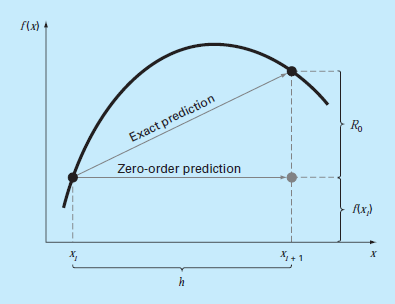

How do we actually measure $R_0$ here when we don't know the true value of $f(x_{i+1})$? We do know $f(x_i)$ and $h=x_{i+1}-x_i$. If we knew the slope, $m$, of the secant between $f(x_i)$ and $f(x_{i+1})$, then we could find $R_0$. We dont. But, we do know something about $m$.

### The Mean-Value Theorem
Let $f$ be continous on interval $[a,b]$ and differentiable on $(a,b)$. Then, there exists a $c \in (a,b)$ such that

$$
f'(c)=\frac{f(b)-f(a)}{b-a}
$$

We can apply this to our situation where $a=x_i$, $b=x_{i+1}$, and $c=\xi$. That is, there exists a $\xi \in (x_i,x_{i+1})$, such that

$$
f'(\xi)=\frac{f(x_{i+1})-f(x_i)}{x_{i+1}-x_i}=\frac{R_0}{h}
$$

Thus, $R_0 = f'(\xi)h$, where $\xi \in (x_i,x_{i+1})$.

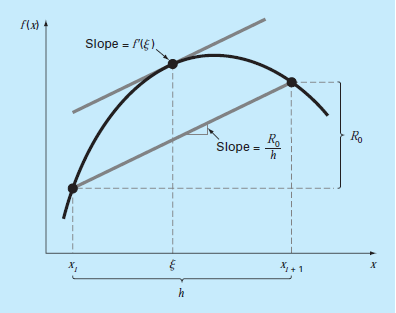

## Taylor Example 3
The Taylor polynomial approximation for $f(x) = e^x$ expanded about $a=0$ is 

$$
e^x \approx 1 + x + \frac{x^2}{2!} + \frac{x^3}{3!} + \dots + \frac{x^n}{n!} 
$$

It is clear from: 
$$
R_n = \frac{f^{(n+1)} (\xi)}{(n+1)!}(x-a)^{n+1} 
$$

that the truncation error of any Taylor polynomial approximation is small when $x$ is close to $a$ (note that $R_n=0$ when $x=a$) and will increase as $x$ gets further away from $a$. Also, as $n$ increases, the Taylor polynomial approximations become better and better approximations to $f(x)$, provided of course that $f^{(n+1)}(x)$ is bounded on some interval containing $x$ and $a$. 

**Additional material**
In addition to the material in the handouts, there is an alternative form for the remainder $R_n$ which can also be
defined as: 

\begin{equation} 
R_n = \int^{x}_{a} \frac{(x-t)^n}{n!} f^{(n+1)}(t)dt 
\end{equation} 

This form is called the *integral form*. The form we covered in
class with the unkown value $\xi$ is referred to as the *derivative* or 
*Lagrange form* of the remainder, named after the
famous mathematician *Joseph-Louis Lagrange (1736-1813)* who
characterized the remainder term and realized the fundamental
importance of Taylor's theorem in calculus. The derivation is based on
the first theorem of mean for integrals which states that if a
function $f$ is continuous and integrable on an interval containing 
$\alpha$ and $x$, then there exists a point $\xi$ between $\alpha$
and $x$ such that: 

\begin{equation} 
\int_{\alpha}^{x} g(t)dt = g(\xi)(x-\alpha) 
\end{equation} 

## The Remainder Term
Consider the remainder term when $n=0$, expanded about some $a$. Then, $f(x) \approx f(a)$ with error term $R_0=f'(\xi)(x-a)$, for some $\xi$ between $x$ and $a$. Where does $\xi$ come from? 